# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Устройство: Colab, GPU T4. Модель cointegrated/rubert-tiny2 (лицензия MIT), revision e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae. Датасет Collection3: https://huggingface.co/datasets/RCC-MSU/collection3, ветка refs/convert/parquet, лицензия в карточке указана как other. Бонусы: 6.3 и 6.5. Источники: документация transformers, datasets и seqeval, материалы курса. Нерешенных задач нет.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Датасет русский, поэтому нужна русская или многоязычная модель. rubert-tiny2 обучена на русском и английском и весит 29M параметров против примерно 180M у DeepPavlov/rubert-base-cased и 280M у xlm-roberta-base, так что дообучение на всем Collection3 идет минуты. По качеству на NER она ожидаемо уступает base-моделям, но для этой задачи скорость важнее, лицензия MIT. Без фиксированной revision владелец может перезалить веса или токенизатор, и тогда поменяются метрики, а при смене словаря сломается разбиение на сабворды.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    count = lambda m: sum(p.numel() for p in m.parameters())
    base = getattr(model, model.base_model_prefix)
    layers = [count(layer) for layer in base.encoder.layer]
    blocks = dict(embeddings=count(base.embeddings), encoder=sum(layers), head=count(model.classifier), layers=layers)
    blocks['other'] = count(model) - blocks['embeddings'] - blocks['encoder'] - blocks['head']
    return blocks

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc['input_ids'].shape), 'attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape))
print('logits', tuple(out.logits.shape))
print(tokenizer.convert_ids_to_tokens(enc['input_ids'][0]))

input_ids (2, 11) attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits (2, 11, 7)
['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.7 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Батч из двух предложений после токенизатора дает input_ids и attention_mask формы (2, 11): у первого предложения 9 сабвордов плюс [CLS] и [SEP], батч выровнен паддингом. Эмбеддинги дают (2, 11, 312), три слоя энкодера сохраняют эту форму (4 hidden_states вместе со входом), голова дает logits (2, 11, 7). Больше всего параметров в эмбеддингах, 26.8M из 29.1M (92.1%): таблица словаря 83828 x 312, а слоев энкодера всего три по 0.77M. Токены обмениваются информацией только в слоях энкодера, эмбеддинги и голова обрабатывают каждый токен отдельно. T больше числа слов, потому что слова режутся на сабворды (Чайковский дает Чайк и ##овский) и добавляются спецтокены.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


In [14]:
for split in raw:
    ents, span_lens, sent_lens = collections.Counter(), collections.Counter(), []
    for tags in raw[split]['ner_tags']:
        t = [LABEL_NAMES[i] for i in tags]
        sent_lens.append(len(t))
        for j, tag in enumerate(t):
            if tag == 'O' or (tag.startswith('I-') and j > 0 and t[j - 1][2:] == tag[2:]):
                continue
            k = j + 1
            while k < len(t) and t[k] == 'I-' + tag[2:]:
                k += 1
            ents[tag[2:]] += 1
            span_lens[min(k - j, 5)] += 1
    print(f'{split}: {len(sent_lens)} предложений, сущности {dict(sorted(ents.items()))}')
    print(f'  длина спана в словах (5 = 5+): {dict(sorted(span_lens.items()))}')
    print(f'  длина предложения: среднее {np.mean(sent_lens):.1f}, медиана {np.median(sent_lens):.0f}, 95% {np.percentile(sent_lens, 95):.0f}, макс {max(sent_lens)}')

train: 9301 предложений, сущности {'LOC': 4881, 'ORG': 5960, 'PER': 7406}
  длина спана в словах (5 = 5+): {1: 9025, 2: 6124, 3: 2068, 4: 373, 5: 657}
  длина предложения: среднее 20.2, медиана 18, 95% 41, макс 256
validation: 2153 предложений, сущности {'LOC': 1168, 'ORG': 1308, 'PER': 1641}
  длина спана в словах (5 = 5+): {1: 2110, 2: 1344, 3: 453, 4: 81, 5: 129}
  длина предложения: среднее 20.4, медиана 18, 95% 41, макс 118
test: 1922 предложений, сущности {'LOC': 1175, 'ORG': 1256, 'PER': 1570}
  длина спана в словах (5 = 5+): {1: 1951, 2: 1306, 3: 540, 4: 86, 5: 118}
  длина предложения: среднее 20.9, медиана 19, 95% 42, макс 122


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 собран из новостей корпуса Persons-1000 и размечен вручную по правилам, близким к MUC-7, в инструменте Brat; перевод в BIO и деление на сплиты сделала команда DeepPavlov. Лицензия в карточке на HF указана как other, датасет открыто распространяется для исследований. Типы PER, ORG и LOC: в train 7406, 5960 и 4881, в validation 1641, 1308 и 1168, в test 1570, 1256 и 1175, совсем редкого типа нет, реже всех LOC. Почти половина спанов из одного слова (9025 из 18247 в train), но есть хвост из 5 и больше слов (657), на нем вероятны ошибки границ. Предложения короткие, медиана 18 слов и 95% не длиннее 41, так что обрезка по 128 сабвордам почти ничего не теряет.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O' or tag.startswith('B-') or tag[2:] != typ:
            if typ is not None:
                spans.append((start, i, typ))
            start, typ = (None, None) if tag == 'O' else (i, tag[2:])
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
Path('data').mkdir(exist_ok=True)
for split in raw:
    path = Path('data') / f'{split}_spans.jsonl'
    with open(path, 'w', encoding='utf-8') as f:
        for ex in raw[split]:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': spans}, ensure_ascii=False) + '\n')
    same = only_spans = 0
    with open(path, encoding='utf-8') as f:
        for line, ex in zip(f, raw[split]):
            row = json.loads(line)
            back = spans_to_bio([tuple(s) for s in row['spans']], len(row['tokens']))
            orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
            if back == orig:
                same += 1
            else:
                assert bio_to_spans(back) == bio_to_spans(orig)
                only_spans += 1
    print(f'{split}: совпало дословно {same}, совпали только спаны (I- без B-) {only_spans}')

train: совпало дословно 9296, совпали только спаны (I- без B-) 5
validation: совпало дословно 2153, совпали только спаны (I- без B-) 0
test: совпало дословно 1921, совпали только спаны (I- без B-) 1


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метрика считается по словам и тег слова берется с его первого сабворда, поэтому метку ставим только туда. Остальные сабворды и спецтокены получают -100, cross-entropy их пропускает, и они не дают вклада ни в loss, ни в градиент. В train по MAX_LENGTH обрезано 10 предложений, без метки осталось 434 слова, это около 0.2% слов train; в метрике такие слова получают O, и если они внутри сущности, это будет пропуск или ошибка границы. Датасет уже в BIO, вложенных и пересекающихся спанов нет; при выгрузке в JSON и обратно дословно не совпали 5 предложений train и 1 test, где I- стоит без B-, но спаны у них совпали.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
baseline = {'majority': entity_scores(val_gold, [predict_majority(tagger, ws) for ws in val_tokens])}
set_seed(SEED)
random_pred = predict_word_tags(make_model(), val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
for name, scores in baseline.items():
    print(name, {k: round(float(v), 4) for k, v in scores.items()})
print('случайная голова, частоты тегов:', collections.Counter(t for tags in random_pred for t in tags).most_common())

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

majority {'f1_micro': 0.5613, 'f1_macro': 0.5786, 'precision': 0.5626, 'recall': 0.5601}
random_head {'f1_micro': 0.0381, 'f1_macro': 0.0353, 'precision': 0.0223, 'recall': 0.1304}
случайная голова, частоты тегов: [('O', 11544), ('I-PER', 11459), ('B-PER', 8688), ('I-LOC', 4833), ('B-LOC', 3053), ('I-ORG', 2511), ('B-ORG', 1768)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн дает F1 0.561 на validation (P 0.563, R 0.560). Он работает, потому что в новостях одни и те же люди, города и организации повторяются, но контекста он не видит, новые слова пропускает, а слово с разными тегами размечает всегда одинаково. Энкодер со случайной головой дает F1 0.038: голова не обучена и выдает почти случайные теги, O среди них 11544 раза, а сущностных тегов больше 32 тысяч, поэтому спанов много и почти все неверные (precision 0.022). Признаки энкодера предобучены, но пока линейная голова не научилась переводить их в теги, они ничего не дают.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier')
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    args = TrainingArguments(out_dir, learning_rate=lr, per_device_train_batch_size=batch_size,
                             per_device_eval_batch_size=64, num_train_epochs=epochs, warmup_steps=0.1,
                             weight_decay=0.01, eval_strategy='steps', eval_steps=max(1, steps // 10),
                             logging_steps=max(1, steps // 10), save_strategy='no', report_to='none',
                             fp16=torch.cuda.is_available(), seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.7025', 'grad_norm': '1.023', 'learning_rate': '0.0001955', 'epoch': '0.299'}
{'eval_loss': '0.1336', 'eval_runtime': '2.285', 'eval_samples_per_second': '942.1', 'eval_steps_per_second': '14.88', 'epoch': '0.299'}
{'loss': '0.1173', 'grad_norm': '1.502', 'learning_rate': '0.0001783', 'epoch': '0.5979'}
{'eval_loss': '0.07041', 'eval_runtime': '0.4896', 'eval_samples_per_second': '4398', 'eval_steps_per_second': '69.45', 'epoch': '0.5979'}
{'loss': '0.08007', 'grad_norm': '0.6521', 'learning_rate': '0.0001562', 'epoch': '0.8969'}
{'eval_loss': '0.0557', 'eval_runtime': '0.4847', 'eval_samples_per_second': '4442', 'eval_steps_per_second': '70.15', 'epoch': '0.8969'}
{'loss': '0.04763', 'grad_norm': '0.6616', 'learning_rate': '0.000134', 'epoch': '1.196'}
{'eval_loss': '0.04864', 'eval_runtime': '0.6348', 'eval_samples_per_second': '3391', 'eval_steps_per_second': '53.56', 'epoch': '1.196'}
{'loss': '0.0435', 'grad_norm': '0.9772', 'learning_rate': '0.0001118', 'epoch': '1.495

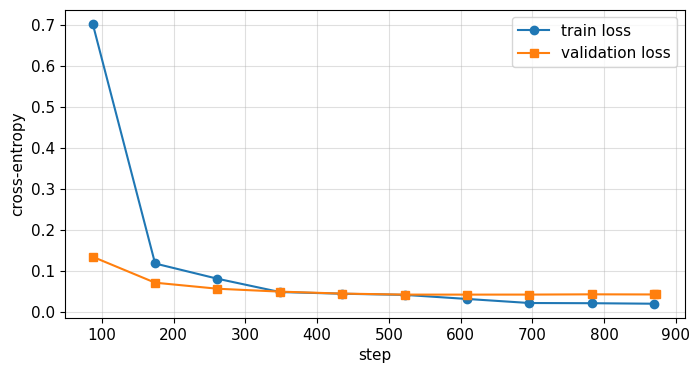

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** LR 2e-4 взят из шаблона под rubert-tiny2: модель маленькая, ей нужен шаг больше, чем 2e-5 у base-моделей. Batch 32, 3 эпохи, warmup 10% шагов, weight decay 0.01, fp16 на GPU. Train loss падает с 0.70 до 0.019, validation loss с 0.134 до 0.041 к концу второй эпохи и дальше держится на уровне 0.041-0.042, то есть третья эпоха на validation ничего не дает и train уходит ниже validation. Больше эпох не нужно. Обучение заняло 50 с на Tesla T4.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for g_seq, p_seq in zip(gold, pred):
        for g, p in zip(g_seq, p_seq):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
print('validation')
print(classification_report(val_gold, val_pred, digits=4, zero_division=0))
print(f'validation: entity F1 {f1_score(val_gold, val_pred):.4f}, token F1 {token_f1(val_gold, val_pred):.4f}')

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
print('\ntest')
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))
report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
final['per_type'] = {t: {k: report[t][k] for k in ['precision', 'recall', 'f1-score', 'support']} for t in ENTITY_TYPES}
print({k: round(float(v), 4) for k, v in final.items() if k != 'per_type'})

validation
              precision    recall  f1-score   support

         LOC     0.9540    0.9409    0.9474      1168
         ORG     0.8304    0.8907    0.8595      1308
         PER     0.9618    0.9823    0.9720      1641

   micro avg     0.9161    0.9415    0.9286      4117
   macro avg     0.9154    0.9380    0.9263      4117
weighted avg     0.9178    0.9415    0.9293      4117

validation: entity F1 0.9286, token F1 0.9533

test
              precision    recall  f1-score   support

         LOC     0.9476    0.9540    0.9508      1175
         ORG     0.8489    0.8814    0.8648      1256
         PER     0.9579    0.9854    0.9714      1570

   micro avg     0.9203    0.9435    0.9318      4001
   macro avg     0.9181    0.9403    0.9290      4001
weighted avg     0.9207    0.9435    0.9319      4001

{'f1_micro': 0.9318, 'f1_macro': 0.929, 'precision': 0.9203, 'recall': 0.9435, 'token_f1': 0.9548}


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего ORG: F1 0.865 на test против 0.951 у LOC и 0.971 у PER. Названия организаций длиннее и разнообразнее, часто стоят в кавычках и внутри содержат места и имена, поэтому модель чаще ошибается в границах и путает тип. Micro F1 0.932 и macro F1 0.929 почти равны, потому что типы близки по числу и ни один не проседает сильно. Токенный F1 0.955 выше F1 по сущностям 0.932: если в длинном спане неверно одно слово, по словам засчитываются остальные, а по сущностям ошибка весь спан. Пользователю NER ближе F1 по сущностям, ему нужна целая сущность с правильными границами.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    result, touched = [], set()
    for g in gold_spans:
        overlap = [p for p in pred_spans if p[0] < g[1] and g[0] < p[1]]
        touched.update(overlap)
        same_type = [p for p in overlap if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif overlap:
            result.append(('type', g, overlap[0]))
        else:
            result.append(('missed', g, None))
    result += [('spurious', None, p) for p in pred_spans if p not in touched]
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts, examples = collections.Counter(), collections.defaultdict(list)
for words, g, p in zip(val_tokens, val_gold, val_pred):
    for cat, gs, ps in categorize_errors(bio_to_spans(g), bio_to_spans(p)):
        counts[cat] += 1
        if cat != 'correct' and len(examples[cat]) < 2:
            examples[cat].append((words, gs, ps))
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(v for c, v in errors.items() if c != 'correct')
print(errors)
print('доли среди ошибок:', {c: round(errors[c] / n_errors, 3) for c in ERROR_CATEGORIES if c != 'correct'})


def show(words, span):
    return None if span is None else (' '.join(words[span[0]:span[1]]), span[2])


for cat in ERROR_CATEGORIES[1:]:
    for words, gs, ps in examples[cat]:
        print(f'\n[{cat}] {" ".join(words)}\n  gold: {show(words, gs)}  pred: {show(words, ps)}')

{'correct': 3876, 'boundary': 161, 'type': 54, 'missed': 26, 'spurious': 115}
доли среди ошибок: {'boundary': 0.452, 'type': 0.152, 'missed': 0.073, 'spurious': 0.323}

[boundary] До работы в Ираке Басс в течение нескольких лет возглавлял Операционный центр по экстренному реагированию Госдепартамента США , обеспечивающий координацию усилий по защите американских граждан , сотрудников и имущества посольств в чрезвычайных ситуациях .
  gold: ('Операционный центр по экстренному реагированию', 'ORG')  pred: ('Операционный центр', 'ORG')

[boundary] Акционеры издательского дома ( ИД ) " Коммерсантъ " согласились на отставку гендиректора Демьяна Кудрявцева .
  gold: ('ИД', 'ORG')  pred: ('ИД )', 'ORG')

[type] Якунин заявил в четверг агентству Прайм , что намерен выяснить , кто стоит за ложным сообщением .
  gold: ('Прайм', 'ORG')  pred: ('Прайм', 'PER')

[type] Адвокат коллегии " Трунов , Айвар и партнеры " Людмилы Айвар : " Уголовной ответственности не наступит , поскольку , когда какое - 

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation 3876 верных спанов и 356 ошибок: границы 161 (45%), лишние спаны 115 (32%), тип 54 (15%), пропуски 26 (7%). В примерах ошибки границ на длинных названиях организаций (Операционный центр по экстренному реагированию обрезан до двух слов) и на скобках и кавычках, ошибки типа на организациях, похожих на имена: агентство Прайм и адвокатская коллегия Трунов, Айвар и партнеры распознаны как PER. Часть ошибок границ спорна и в самой разметке, например где кончается название в кавычках и со скобкой. Чтобы уменьшить ошибки границ, стоит добавить в train больше длинных названий организаций или взять модель крупнее, которая лучше держит контекст.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
set_seed(SEED)
frozen = make_model()
history_frozen, seconds_frozen = train_ner(frozen, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
ablation = dict(
    setting=ABLATION,
    full=dict(entity_scores(val_gold, val_pred), seconds=RUN_TIMES['train_main_sec'],
              trainable=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    freeze=dict(entity_scores(val_gold, predict_word_tags(frozen, val_tokens)), seconds=seconds_frozen,
                trainable=sum(p.numel() for p in frozen.parameters() if p.requires_grad)))
for name in ['full', 'freeze']:
    print(name, {k: round(float(v), 4) for k, v in ablation[name].items()})

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.587', 'grad_norm': '2.791', 'learning_rate': '0.0001955', 'epoch': '0.299'}
{'eval_loss': '1.089', 'eval_runtime': '0.5425', 'eval_samples_per_second': '3969', 'eval_steps_per_second': '62.67', 'epoch': '0.299'}
{'loss': '0.7583', 'grad_norm': '0.7215', 'learning_rate': '0.0001783', 'epoch': '0.5979'}
{'eval_loss': '0.5258', 'eval_runtime': '0.4991', 'eval_samples_per_second': '4314', 'eval_steps_per_second': '68.12', 'epoch': '0.5979'}
{'loss': '0.5', 'grad_norm': '0.5032', 'learning_rate': '0.0001562', 'epoch': '0.8969'}
{'eval_loss': '0.3989', 'eval_runtime': '0.491', 'eval_samples_per_second': '4385', 'eval_steps_per_second': '69.25', 'epoch': '0.8969'}
{'loss': '0.4076', 'grad_norm': '0.4222', 'learning_rate': '0.000134', 'epoch': '1.196'}
{'eval_loss': '0.342', 'eval_runtime': '0.5079', 'eval_samples_per_second': '4239', 'eval_steps_per_second': '66.94', 'epoch': '1.196'}
{'loss': '0.3715', 'grad_norm': '0.4203', 'learning_rate': '0.0001118', 'epoch': '1.495'}
{'eval_

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** С замороженным энкодером учится только голова, 2191 параметр вместо 29.1M, и F1 на validation падает с 0.929 до 0.615. Обучение быстрее не во столько же раз: 18 с против 50 с на T4, потому что прямой проход через энкодер остается, экономится только обратный. Признаки предобученного энкодера не настроены на NER, и одна линейная голова поверх них плохо находит границы и тип. Чтобы вывод был надежнее, стоит повторить на нескольких seed и дать замороженной голове больше эпох, чтобы отделить нехватку обучения от нехватки признаков.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообученная rubert-tiny2 на Collection3 дает F1 по сущностям 0.932 на test, на validation 0.929 против 0.561 у словарного бейзлайна и 0.038 у необученной головы. Лучше всего распознаются PER (0.971) и LOC (0.951), хуже ORG (0.865). Среди ошибок на validation больше всего ошибок границ (45%) и лишних спанов (32%). Дообучать нужно энкодер целиком: с замороженным F1 только 0.615. Модель сильно зависит от регистра, в нижнем регистре F1 падает до 0.0555 (бонус 6.3). Ограничения: один датасет новостей, три типа, маленькая модель и один seed. Дальше стоит сравнить с base-моделью и проверить на текстах другого домена.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.928605654048874, "f1_macro": 0.9262792877547099, "precision": 0.9160954857007799, "recall": 0.9414622297789653, "seconds": 49.735722485999986, "trainable": 29098303}, "freeze": {"f1_micro": 0.6147704590818363, "f1_macro": 0.596307815015719, "precision": 0.6319569120287253, "recall": 0.5984
final F1 micro 0.9318


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** 

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    rng = random.Random(SEED)

    def typo(w):
        if len(w) < 4 or rng.random() > 0.3:
            return w
        i = rng.randrange(1, len(w) - 1)
        return w[:i] + w[i + 1] + w[i] + w[i + 2:]

    corruptions = {'clean': lambda w: w, 'lower': str.lower, 'upper': str.upper, 'typo': typo}
    shift = {name: f1_score(val_gold, predict_word_tags(model, [[f(w) for w in ws] for ws in val_tokens]))
             for name, f in corruptions.items()}
    print({k: round(float(v), 4) for k, v in shift.items()})

{'clean': 0.9286, 'lower': 0.0555, 'upper': 0.0681, 'typo': 0.8493}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего роняет F1 смена регистра: в нижнем регистре 0.0555, в верхнем 0.0681 против 0.9286 на чистом validation, а опечатки в 30% слов длиннее 3 букв дают 0.8493. Заглавная буква в начале слова для этой cased модели главный признак сущности, а после смены регистра токенизатор режет слово на другие сабворды, которых модель в таком контексте не видела. Опечатка портит один-два сабворда, остальная часть слова и контекст сохраняются, поэтому падение меньше.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** 

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean: лучший порог 0.81, F1 0.9356 (P 0.9434, R 0.9279), при пороге 0 F1 0.9286
min: лучший порог 0.74, F1 0.9349 (P 0.9445, R 0.9254), при пороге 0 F1 0.9286


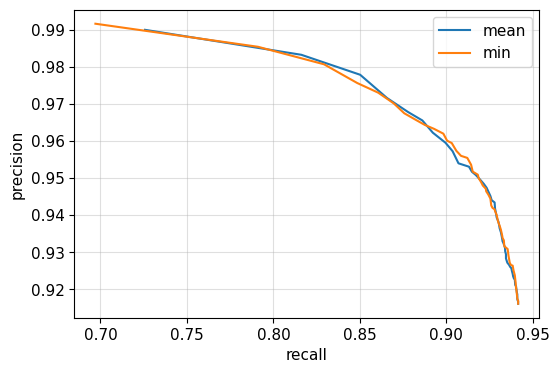

In [34]:
if '6.5' in BONUS_TASKS:
    val_tags, val_conf = predict_word_tags(model, val_tokens, return_probs=True)
    gold_set = {(i, s) for i, g in enumerate(val_gold) for s in bio_to_spans(g)}
    scored = {'mean': [], 'min': []}
    for i, (tags, conf) in enumerate(zip(val_tags, val_conf)):
        for s in bio_to_spans(tags):
            scored['mean'].append((float(np.mean(conf[s[0]:s[1]])), (i, s)))
            scored['min'].append((min(conf[s[0]:s[1]]), (i, s)))
    thresholds = np.round(np.arange(0, 1, 0.01), 2)
    plt.figure(figsize=(6, 4))
    for agg, items in scored.items():
        curve = []
        for th in thresholds:
            kept = {sp for c, sp in items if c >= th}
            tp = len(kept & gold_set)
            p, r = (tp / len(kept) if kept else 0.0), tp / len(gold_set)
            curve.append((p, r, 2 * p * r / (p + r) if tp else 0.0))
        p, r, f = map(np.array, zip(*curve))
        best = int(f.argmax())
        print(f'{agg}: лучший порог {thresholds[best]}, F1 {f[best]:.4f} (P {p[best]:.4f}, R {r[best]:.4f}), при пороге 0 F1 {f[0]:.4f}')
        plt.plot(r, p, label=agg)
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** По средней уверенности лучший порог 0.81 дает F1 0.9356 против 0.9286 при пороге 0, прибавка 0.007; по минимальной лучший порог 0.74 и F1 0.9349. Минимальная строже к длинным спанам, одно неуверенное слово тянет вниз весь спан, поэтому на лучшем пороге у нее выше precision (0.9445 против 0.9434) и ниже recall (0.9254 против 0.9279). Порог только отбрасывает уже предсказанные спаны и не добавляет новых, поэтому recall он поднять не может.